In [11]:
# Cell 1: Setup and streaming aggregation with multiple test functions
%env XLA_PYTHON_CLIENT_PREALLOCATE=False

import jax
jax.config.update("jax_enable_x64", False)
import jax.numpy as jnp
import pickle
import os
import matplotlib.pyplot as plt
import numpy as np

DIRS = ["./dim2_20_gaussian_small_rw/"]
# --- Define multiple test functions ---

mu = np.array([3., 0.])
f_tests = {
    "x": lambda x: x[..., 0],
    #"x2": lambda x: x[..., 0]**2,
    #"r1": lambda x: (jnp.linalg.norm(x - mu, axis=-1) > 1.).astype(float),
    #"r2": lambda x: (jnp.linalg.norm(x - mu, axis=-1) > 2.).astype(float),
    #"r3": lambda x: (jnp.linalg.norm(x - mu, axis=-1) > 3.).astype(float),
}

# --- Storage for aggregated moment estimates ---
data = {DIR: {fname: {} for fname in f_tests} for DIR in DIRS}

for DIR in DIRS:
    print(f"\nProcessing DIR: {DIR}")
    for file in os.listdir(DIR):
        if file.endswith(".pkl") and file.startswith("__"):
            with open(os.path.join(DIR, file), "rb") as f:
                my_pkl = pickle.load(f)

            factor = my_pkl['config']['factor']
            mean = my_pkl['config']['mean']
            cov = my_pkl['config']['cov']
            num_steps = my_pkl['config'].get('num_mcmc_steps', None)
            print(f"File: {file}, factor={factor}, MCMC steps={num_steps}")

            particles = my_pkl['res'][0]  # shape (num_runs, num_particles, dim)
            print(f"Particles shape: {particles.shape}")

            # Optional: quick histogram to check distribution
            #if factor >= 3.7 and factor < 4:
            #    for j in range(particles.shape[0]):
            #        plt.hist(particles[j, ..., 0].ravel(), bins=1000)
            #        plt.title(f"{DIR} — factor={factor} - run={j}")
            #        plt.show()

            # --- Compute moment estimates for all test functions ---
            for fname, f_test in f_tests.items():
                vals = jnp.mean(f_test(particles), axis=[-1, -2])
                vals = np.asarray(vals).ravel()

                if factor not in data[DIR][fname]:
                    data[DIR][fname][factor] = []

                data[DIR][fname][factor].append(vals)

            del my_pkl  # free memory

# --- Placeholder for ground truth (to be filled later) ---
true_val = {DIR: {fname: None for fname in f_tests} for DIR in DIRS}

# Student-t target (dim2_20_student*): t_3((3, 0), I)
# nu = 3.
# true_val = {DIR: {"x": {1.0: 3.}, "x2": {1.0: 12.}} | {f"r{r}": {1.0: (1 + r**2 / nu) ** (-nu / 2)} for r in (3, 5, 8)}
#             for DIR in DIRS}

# Gaussian target (dim2_20_gaussian_small_rw): N((3, 0), I), so |x - mu|^2 ~ chi2_2
true_val = {DIR: {"x": {1.0: 3.}, "x2": {1.0: 10.}} | {f"r{r}": {1.0: np.exp(-r**2 / 2)} for r in (1, 2, 3)}
            for DIR in DIRS}

env: XLA_PYTHON_CLIENT_PREALLOCATE=False

Processing DIR: ./dim2_20_gaussian_small_rw/
File: __factor1.1000_greedy_xp.py_1026133258.pkl, factor=1.1, MCMC steps=100
Particles shape: (1000, 1, 20, 221, 2)
File: __factor2.2000_greedy_xp.py_1026133356.pkl, factor=2.2, MCMC steps=100
Particles shape: (1000, 1, 20, 441, 2)
File: __factor2.6000_greedy_xp.py_1026133414.pkl, factor=2.6, MCMC steps=100
Particles shape: (1000, 1, 20, 521, 2)
File: __factor3.6000_greedy_xp.py_1026133510.pkl, factor=3.6, MCMC steps=100
Particles shape: (1000, 1, 20, 721, 2)
File: __factor1.6000_greedy_xp.py_1026133326.pkl, factor=1.6, MCMC steps=100
Particles shape: (1000, 1, 20, 321, 2)
File: __factor3.7000_greedy_xp.py_1026133517.pkl, factor=3.7, MCMC steps=100
Particles shape: (1000, 1, 20, 741, 2)
File: __factor1.5000_greedy_xp.py_1026133319.pkl, factor=1.5, MCMC steps=100
Particles shape: (1000, 1, 20, 301, 2)
File: __factor1.3000_greedy_xp.py_1026133309.pkl, factor=1.3, MCMC steps=100
Particles shape: (1000, 

(array([  45.,  689., 3047., 2989.,  888.,  648., 2889., 3758.,  972.,
         115.]),
 array([-5.64646435, -4.44229889, -3.23813367, -2.03396845, -0.82980299,
         0.37436247,  1.57852745,  2.78269291,  3.98685837,  5.19102383,
         6.39518929]),
 <BarContainer object of 10 artists>)

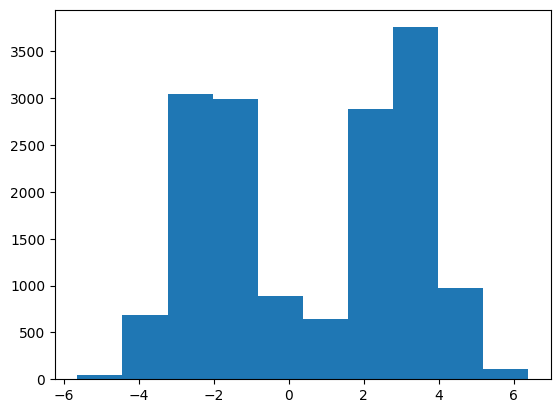

In [57]:
plt.hist(particles[3][..., 0].reshape(-1))

<>:106: SyntaxWarning: invalid escape sequence '\h'
<>:106: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_2679834/3151966909.py:106: SyntaxWarning: invalid escape sequence '\h'
  ax_mse.set_ylabel("MSE of $\hat{\pi}_T(f)$")


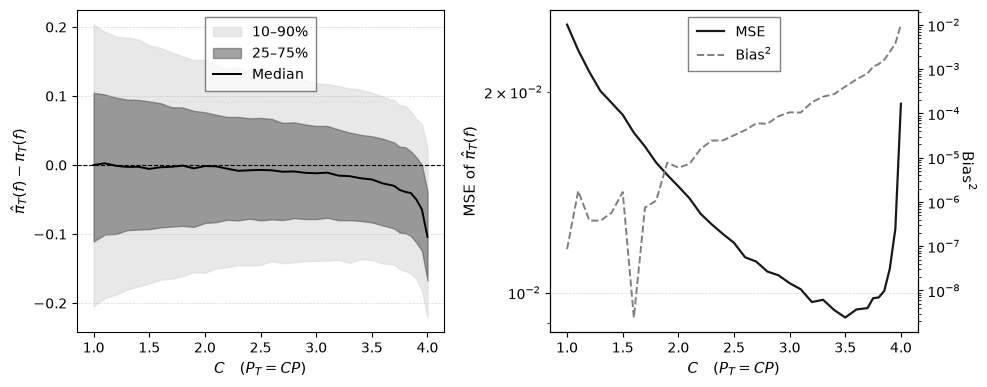

In [13]:
import matplotlib.pyplot as plt
import numpy as np

titles = {
    "./power2WFgreedy_pas_mal_dim5": "Bimodal Gaussian",
    "./power2WFgreedy_gaussian/": "Gaussian"
}

use_dual_axis = True  # for MSE/Bias² plot

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "axes.linewidth": 0.8,
})

n_tests = len(f_tests)
n_dirs = len(DIRS)  # number of datasets
n_rows = n_dirs * n_tests

# --- Create figure: one row per (DIR, test function), cols = 2
fig, axes = plt.subplots(
    n_rows, 2,
    figsize=(10, 4 * n_rows),
    sharex=False
)

# Make sure axes is 2D
if n_rows == 1:
    axes = axes[np.newaxis, :]

for j_dir, DIR in enumerate(DIRS):
    for i_test, (fname, f_test) in enumerate(f_tests.items()):
        row = j_dir * n_tests + i_test
        ax_quantiles = axes[row, 0]
        ax_mse = axes[row, 1]

        factor_list = sorted(data[DIR][fname].keys())
        x_vals = np.array(factor_list)
        true_val_factor = true_val[DIR][fname][1.0]

        q10, q25, q50, q75, q90 = [], [], [], [], []
        mse_list, bias_squared_list = [], []

        for factor in factor_list:
            vals = np.concatenate(data[DIR][fname][factor], axis=0)
            dev = vals - true_val_factor

            q10.append(np.percentile(dev, 10))
            q25.append(np.percentile(dev, 25))
            q50.append(np.percentile(dev, 50))
            q75.append(np.percentile(dev, 75))
            q90.append(np.percentile(dev, 90))

            bias_sq = np.mean(dev)**2
            var = np.var(dev)
            mse_list.append(bias_sq + var)
            bias_squared_list.append(bias_sq)

        q10, q25, q50, q75, q90 = map(np.array, (q10, q25, q50, q75, q90))
        mse_list = np.array(mse_list)
        bias_squared_list = np.array(bias_squared_list)

        # --- LEFT: Quantiles ---
        ax_quantiles.fill_between(x_vals, q10, q90, color="#d9d9d9", alpha=0.6, label="10–90%")
        ax_quantiles.fill_between(x_vals, q25, q75, color="#4a4a4a", alpha=0.5, label="25–75%")
        ax_quantiles.plot(x_vals, q50, color="black", linewidth=1.4, label="Median")

        ax_quantiles.axhline(0, color="black", linestyle="--", linewidth=0.8)
        ax_quantiles.set_xlabel(r"$C \quad (P_T = C P)$")
        ax_quantiles.set_ylabel(r"$\hat{\pi}_T(f) - \pi_T(f)$")
        ax_quantiles.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.5)
        if n_rows > 1:
            ax_quantiles.set_title(f"{titles.get(DIR, DIR)}, f = {fname}" if n_tests > 1 else titles.get(DIR, DIR))
        if row == 0:
            ax_quantiles.legend(frameon=True, facecolor="white", edgecolor="0.3",
                                framealpha=0.7, fancybox=False, borderpad=0.6, loc="upper center")

        # --- RIGHT: MSE / Bias² ---
        ax_mse.plot(x_vals, mse_list, color="black", linewidth=1.6, alpha=0.9, label="MSE")

        if use_dual_axis:
            ax_right = ax_mse.twinx()
            ax_right.plot(x_vals, bias_squared_list, color="#7f7f7f", linestyle="--", linewidth=1.4, label=r"Bias$^2$")
            ax_right.set_ylabel(r"Bias$^2$", rotation=270, labelpad=12)
            ax_right.set_yscale("log")
        else:
            ax_mse.plot(x_vals, bias_squared_list, color="#7f7f7f", linestyle="--", linewidth=1.4, label=r"Bias$^2$")

        ax_mse.set_yscale("log")
        ax_mse.grid(axis='y', linestyle='--', linewidth=0.5, alpha=0.5)
        ax_mse.set_xlabel(r"$C \quad (P_T = C P)$")
        ax_mse.set_ylabel(r"MSE of $\hat{\pi}_T(f)$")

        # --- Legend only on first row ---
        if row == 0:
            handles = [ax_mse.lines[0]]
            labels = ["MSE"]
            if use_dual_axis:
                handles.append(ax_right.lines[0])
                labels.append(r"Bias$^2$")
            ax_mse.legend(handles=handles, labels=labels, loc="upper center",
                          frameon=True, facecolor="white", edgecolor="0.3",
                          framealpha=0.7, fancybox=False, borderpad=0.6)


plt.tight_layout()
plt.savefig("combined_quantiles_mse_multitest.pdf", dpi=300)
plt.show()